# Looking at the engine runs before any model

Each row is one cycle of one simulated turbofan. The last cycle of a training engine is failure. We are using this file as a proxy for turboshaft wear, not as an Apache recording. The limits of that proxy are in `DATA_SOURCES.md`.

This notebook does not train. `scripts/train.py` trains.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent
sys.path.insert(0, str(root / "src"))

import matplotlib.pyplot as plt

from rotorcraft_pdm.data.cmapss import load_subset

loaded = load_subset("FD001")
train = loaded["train"]
print("rows", len(train), "engines", train["unit"].nunique())
print("dropped constant sensors", loaded["dropped_sensors"])
train.head()

rows 20631 engines 100
dropped constant sensors ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,125.0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,125.0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,125.0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,125.0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,125.0


## The cap is visible

Remaining life is clipped at 125. Early cycles sit on that ceiling. The model is not asked to tell 200 cycles from 300 cycles when the sensors have not moved yet.

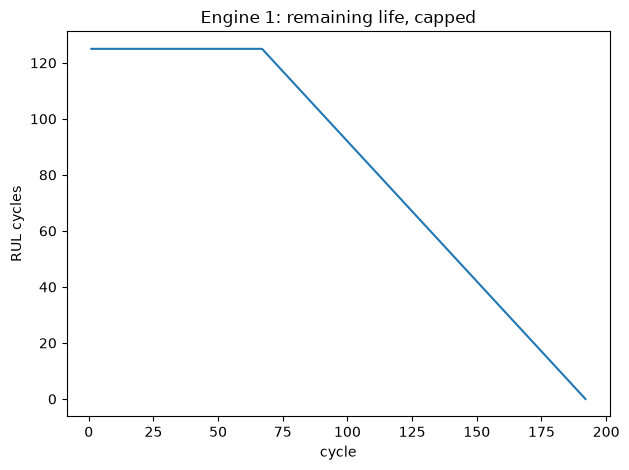

In [2]:
one = train[train["unit"] == 1]
one.plot(x="cycle", y="rul", legend=False)
plt.title("Engine 1: remaining life, capped")
plt.ylabel("RUL cycles")
plt.tight_layout()
plt.show()

## A sensor that moves, and one that does not

Sensor 2 is low-pressure compressor outlet temperature in the NASA notes. It tends to climb as the engine wears. A constant sensor is dropped before training.

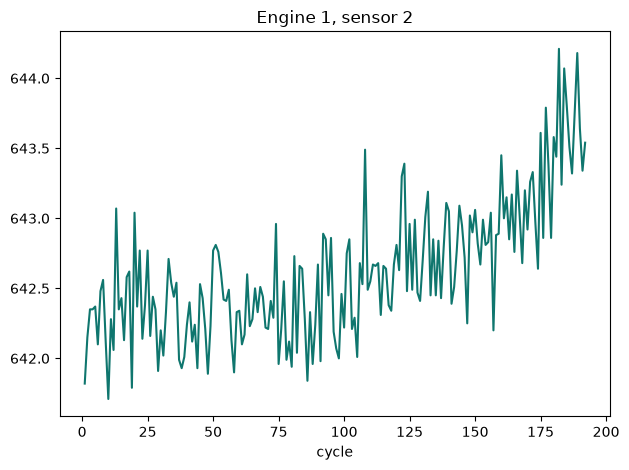

In [3]:
one.plot(x="cycle", y="sensor_2", legend=False, color="#0f766e")
plt.title("Engine 1, sensor 2")
plt.tight_layout()
plt.show()